# Анализ 500 фильмов: получение данных через API, тематическое моделирование и машинное обучение

**Цель проекта** — собрать сведения о фильмах через API, подготовить единый датасет и исследовать его с помощью анализа текста, кластеризации и классификации.

В работе рассматриваются:
1. получение данных из API;
2. очистка и проверка датасета;
3. описательный анализ;
4. тематическое моделирование описаний фильмов;
5. кластеризация фильмов по текстовым признакам;
6. классификация фильмов по условной категории рейтинга;
7. выводы и ограничения.

## 1. Постановка задачи

Нужно получить до 500 фильмов и привести их к единому формату: название, год, страны, жанры, рейтинг и описание. Затем проверить качество данных и выяснить, можно ли обнаружить группы фильмов по описаниям и жанрам.

## 2. Подключение библиотек

In [1]:
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

## 3. Настройка API

В примере используется API сервиса Poiskkino.dev. 

Параметр limit ограничивает число фильмов в одном запросе, а page позволяет получать следующие страницы. В коде ниже делается несколько запросов, пока не будет собрано 500 записей или API не перестанет возвращать результаты.

In [2]:
API_KEY = "YY9XZ29-X0J494V-KTSHEPZ-C611YC0"
BASE_URL = "https://api.poiskkino.dev/v1.4/movie"

headers = {
    "accept": "application/json",
    "X-API-KEY": API_KEY
}

TARGET_MOVIES = 500
PAGE_SIZE = 250

## 4. Получение данных из API

Функция get_movies получает одну страницу и возвращает список фильмов. Отдельная функция get_field аккуратно извлекает значения из полей, которые API может возвращать как списки словарей. Это нужно, например, для стран и жанров.

In [3]:
def get_movies(page, limit=250):
    params = {
        "page": page,
        "limit": limit,
        "selectFields": [
            "id", "name", "year", "description",
            "countries", "genres", "rating"
        ]
    }

    response = requests.get(
        BASE_URL,
        headers=headers,
        params=params,
        timeout=30
    )
    response.raise_for_status()
    data = response.json()

    if isinstance(data, dict):
        return data.get("docs", [])
    if isinstance(data, list):
        return data
    return []


def get_field(value):
    if value is None:
        return None
    if isinstance(value, list):
        names = []
        for item in value:
            if isinstance(item, dict):
                name = item.get("name")
                if name:
                    names.append(str(name))
            elif item:
                names.append(str(item))
        return ", ".join(names) if names else None
    if isinstance(value, dict):
        return value.get("name")
    return value

In [4]:
movies = []

for page in range(1, 10):
    batch = get_movies(page, PAGE_SIZE)
    movies.extend(batch)
    print(f"Страница {page}: получено {len(batch)} фильмов; всего {len(movies)}")

    if len(movies) >= TARGET_MOVIES:
        break

movies = movies[:TARGET_MOVIES]
print("Всего получено записей:", len(movies))

Страница 1: получено 250 фильмов; всего 250
Страница 2: получено 250 фильмов; всего 500
Всего получено записей: 500


## 5. Приведение ответа API к таблице

Ответ API обычно содержит вложенные поля: рейтинг может быть объектом, а жанры и страны — списками. Здесь они преобразуются в удобные для анализа столбцы. Если конкретное поле отсутствует, в таблице останется пропуск, который будет обработан на следующем этапе.

In [5]:
def extract_rating(value):
    if isinstance(value, dict):
        return value.get("kp", value.get("imdb"))
    return value


rows = []
for movie in movies:
    rows.append({
        "movie_id": movie.get("id"),
        "title": movie.get("name"),
        "year": movie.get("year"),
        "country": get_field(movie.get("countries")),
        "genre": get_field(movie.get("genres")),
        "rating": extract_rating(movie.get("rating")),
        "description": movie.get("description")
    })

df = pd.DataFrame(rows)
display(df.head())
print("Размер таблицы:", df.shape)

,movie_id,title,year,country,genre,rating,description
0,14420728,None,NaN,None,биография,NaN,None
1,14563620,Непростые отношения,2026.0,Россия,мелодрама,NaN,"Катя — медсестра в частной клинике, одна воспи..."
2,14552734,Страшное кино,2025.0,"Испания, Португалия",документальный,6.3,Во время летних каникул в Лиссабоне режиссер-д...
3,14555492,Я уезжаю в Виго!,2025.0,Бразилия,документальный,8.4,"О творчестве режиссёра Карлуса Диегиса, которы..."
4,14549521,None,2025.0,Индия,None,6.8,None


Размер таблицы: (500, 7)


## 6. Первичная проверка данных

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   movie_id     500 non-null    int64  
 1   title        302 non-null    object 
 2   year         476 non-null    float64
 3   country      492 non-null    object 
 4   genre        495 non-null    object 
 5   rating       145 non-null    float64
 6   description  196 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 27.5+ KB


In [7]:
display(df.isna().sum().to_frame("Количество пропусков"))
print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов по идентификатору:", df["movie_id"].duplicated().sum())

,Количество пропусков
movie_id,0
title,198
year,24
country,8
genre,5
rating,355
description,304


Полных дубликатов: 0
Дубликатов по идентификатору: 0


## 7. Очистка и подготовка датасета

Сначала убираются повторные записи по идентификатору фильма, затем приводятся к числовому формату год и рейтинг. Названия и описания очищаются от лишних пробелов. Строки без названия удаляются, поскольку по ним невозможно идентифицировать фильм.

Не удаляем все строки с любым пропуском: у фильма может быть название и описание, даже если неизвестна страна или рейтинг. Это сохраняет больше данных для анализа.

In [8]:
df = df.drop_duplicates(subset="movie_id", keep="first")
df["title"] = df["title"].astype("string").str.strip()
df["description"] = df["description"].fillna("").astype(str).str.strip()
df["genre"] = df["genre"].fillna("Не указан").astype(str)
df["country"] = df["country"].fillna("Не указана").astype(str)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

df = df[df["title"].notna() & (df["title"] != "")]
df = df.reset_index(drop=True)

print("После очистки:", df.shape)
display(df.head())

После очистки: (302, 7)


,movie_id,title,year,country,genre,rating,description
0,14563620,Непростые отношения,2026.0,Россия,мелодрама,NaN,"Катя — медсестра в частной клинике, одна воспи..."
1,14552734,Страшное кино,2025.0,"Испания, Португалия",документальный,6.3,Во время летних каникул в Лиссабоне режиссер-д...
2,14555492,Я уезжаю в Виго!,2025.0,Бразилия,документальный,8.4,"О творчестве режиссёра Карлуса Диегиса, которы..."
3,14629255,За закрытыми дверями,2026.0,Россия,мелодрама,NaN,"Желая сбежать от прошлых проблем, Мила вместе ..."
4,14521410,Тень победы,NaN,Россия,детектив,NaN,Лето 1945 года. Бывший учитель Андрей Мартынов...


In [9]:
print("Число уникальных фильмов:", df["movie_id"].nunique())
print("Диапазон годов:", df["year"].min(), "—", df["year"].max())
print("Заполненность описаний:", (df["description"].str.len() > 0).mean().round(3))

Число уникальных фильмов: 302
Диапазон годов: 1959.0 — 2027.0
Заполненность описаний: 0.636


## 8. Сохранение исходного датасета

In [10]:
df.to_csv("films_500.csv", index=False, encoding="utf-8-sig")
print("Датасет сохранён в films_500.csv")

Датасет сохранён в films_500.csv


## 9. Разведочный анализ данных

На этом этапе проверяем распределение рейтингов и годов выпуска, а также самые распространённые жанры. Графики помогают увидеть перекосы выборки и возможные ограничения последующего моделирования.

In [11]:
display(df[["year", "rating"]].describe().round(2))

,year,rating
count,290.00,36.00
mean,2022.31,6.51
std,6.82,1.17
min,1959.00,4.10
25%,2020.00,5.70
50%,2025.00,6.35
75%,2026.00,7.20
max,2027.00,9.10


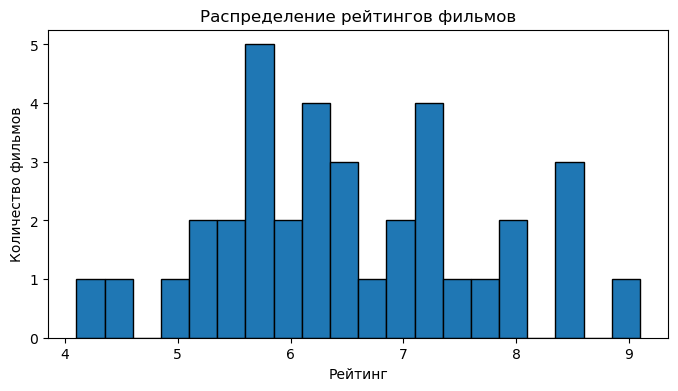

In [12]:
plt.figure(figsize=(8, 4))
df["rating"].dropna().plot(kind="hist", bins=20, edgecolor="black")
plt.title("Распределение рейтингов фильмов")
plt.xlabel("Рейтинг")
plt.ylabel("Количество фильмов")
plt.show()

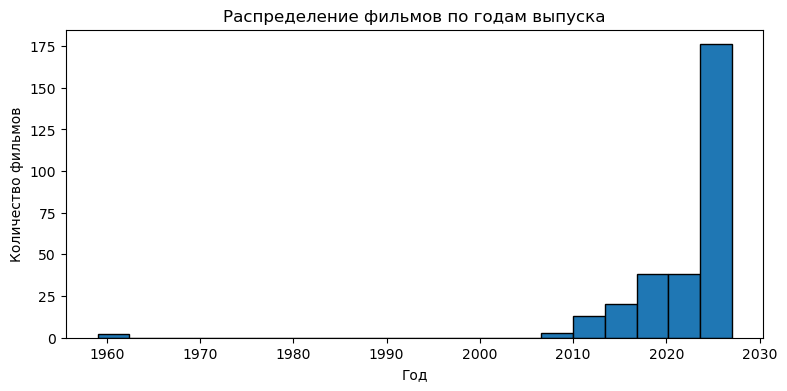

In [13]:
plt.figure(figsize=(9, 4))
df["year"].dropna().astype(int).plot(kind="hist", bins=20, edgecolor="black")
plt.title("Распределение фильмов по годам выпуска")
plt.xlabel("Год")
plt.ylabel("Количество фильмов")
plt.show()

,Количество
genre,
документальный,87
короткометражка,75
драма,63
комедия,47
мультфильм,25
мелодрама,25
реальное ТВ,24
концерт,17
спорт,14


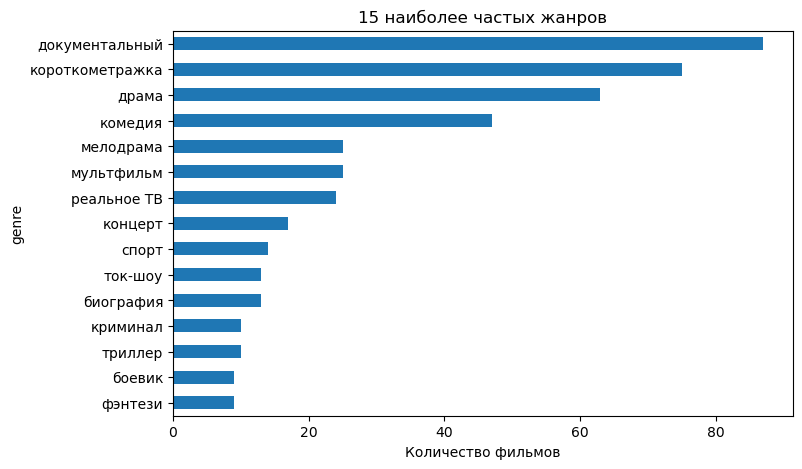

In [14]:
genre_counts = (
    df["genre"].str.split(", ").explode()
    .replace("Не указан", np.nan).dropna()
    .value_counts().head(15)
)
display(genre_counts.to_frame("Количество"))
genre_counts.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("15 наиболее частых жанров")
plt.xlabel("Количество фильмов")
plt.show()

## 10. Подготовка текста

Для тематического моделирования и кластеризации используем описания фильмов. Пустые описания не несут текстовой информации, поэтому для текстовых моделей оставим только записи, где описание не пустое. Векторизатор TF–IDF преобразует слова в числовые признаки и уменьшает вес слов, которые встречаются почти во всех описаниях.

In [15]:
text_df = df[df["description"].str.strip().ne("")].copy()
text_df = text_df.reset_index(drop=True)

print("Фильмов с описанием:", len(text_df))

Фильмов с описанием: 192


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    max_features=3000,
    min_df=2,
    ngram_range=(1, 2)
)
X_text = vectorizer.fit_transform(text_df["description"])

print("Размер матрицы TF-IDF:", X_text.shape)

Размер матрицы TF-IDF: (192, 774)


## 11. Тематическое моделирование с помощью LDA

LDA (Latent Dirichlet Allocation) — модель, которая описывает документы как смеси тем, а темы — как наборы характерных слов. Мы используем счётчики слов, потому что классическая LDA обучается на частотах слов, а не на TF–IDF.

Количество тем задаётся параметром `N_TOPICS`. Оно не обязано совпадать с реальными жанрами: темы — это статистические закономерности в текстах, и их нужно интерпретировать по ключевым словам.

In [17]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

count_vectorizer = CountVectorizer(
    lowercase=True,
    max_features=3000,
    min_df=2,
    ngram_range=(1, 2)
)
X_counts = count_vectorizer.fit_transform(text_df["description"])

N_TOPICS = 6
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=42,
    learning_method="batch",
    max_iter=10
)
topic_weights = lda.fit_transform(X_counts)

In [18]:
words = count_vectorizer.get_feature_names_out()

for topic_id, component in enumerate(lda.components_):
    top_indices = component.argsort()[-10:][::-1]
    top_words = [words[i] for i in top_indices]
    print(f"Тема {topic_id + 1}: " + ", ".join(top_words))

Тема 1: на, из, что, для, их, свою, ради, его, по, сталкиваются
Тема 2: на, они, его, ее, по, что, люди, но, жизнь, чтобы
Тема 3: на, не, его, что, чтобы, за, которые, их, но, рассказывают
Тема 4: на, его, от, не, но, он, из, по, для, до
Тема 5: что, на, она, вместе, война, которая, их, не, по, из
Тема 6: не, за, как, его, на, из, где, чтобы, время, после


Ключевые слова каждой темы нужно прочитать и дать теме осмысленное название. Например, если среди слов часто встречаются «детектив», «убийство», «следствие», тему можно интерпретировать как криминальный сюжет. Название нельзя назначать автоматически только по номеру темы — оно зависит от полученных слов.

In [19]:
text_df["main_topic"] = topic_weights.argmax(axis=1) + 1
df = df.merge(
    text_df[["movie_id", "main_topic"]],
    on="movie_id",
    how="left"
)
display(df[["title", "genre", "main_topic"]].head(10))

,title,genre,main_topic
0,Непростые отношения,мелодрама,6.0
1,Страшное кино,документальный,6.0
2,Я уезжаю в Виго!,документальный,6.0
3,За закрытыми дверями,мелодрама,2.0
4,Тень победы,детектив,5.0
5,Плач осени,мелодрама,NaN
6,Котяткины друзья,"мультфильм, детский",NaN
7,Спутнички,"мультфильм, приключения, семейный",4.0
8,Народные сказки,"мультфильм, детский",NaN
9,Творимые души,документальный,2.0


## 12. Кластеризация фильмов

Кластеризация K-means группирует фильмы по близости их TF–IDF-векторов. В отличие от классификации, заранее известные правильные классы здесь не нужны. Число кластеров задаётся параметром `N_CLUSTERS`; это исследовательский выбор, а не утверждение, что в данных объективно существует именно столько групп.

In [20]:
from sklearn.cluster import KMeans

N_CLUSTERS = 6
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
text_df["cluster"] = kmeans.fit_predict(X_text)

display(
    text_df[["title", "genre", "cluster"]]
    .sort_values("cluster")
    .head(20)
)

C:\Users\Liliann\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Liliann\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Liliann\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Liliann\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^

,title,genre,cluster
165,Концерт Ирины Мягковой «Взрослая»,"короткометражка, комедия, концерт",0
149,Неzлобин. Концерт,"комедия, концерт",0
10,Долгие будни в лаборатории,"короткометражка, драма",1
9,"Горизонт, прожектор, яблоко, пепел, кочегар","драма, короткометражка",1
48,Феномен Седова,"документальный, биография",1
52,Тела,"короткометражка, документальный",1
24,Порталы,"короткометражка, документальный, мультфильм",1
21,Да,"короткометражка, мультфильм",1
103,Подарочек,комедия,1
101,Последователь: Легенда Wu-Tang Clan,"документальный, биография, музыка",1


In [21]:
for cluster_id in sorted(text_df["cluster"].unique()):
    titles = text_df.loc[text_df["cluster"] == cluster_id, "title"].head(8).tolist()
    print(f"Кластер {cluster_id}: {', '.join(titles)}")

Кластер 0: Неzлобин. Концерт, Концерт Ирины Мягковой «Взрослая»
Кластер 1: Горизонт, прожектор, яблоко, пепел, кочегар, Долгие будни в лаборатории, Да, Порталы, Свободу Леонарду Пелтиеру, Феномен Седова, Тела, Укрытие
Кластер 2: Другая Земля, Конвейер, Омут, Ветер в один прекрасный день, Царь-корнишон, Ближний свет, Кае не страшно, Спаси меня снова
Кластер 3: Непростые отношения, Страшное кино, Спутнички, Творимые души, Шалом, Одиночество ящериц, Бродяга, Обычный день
Кластер 4: Язык их снов, Воскресенье, Адюльтер, Соседский дозор, Не забывай меня, Сетка, Что я наделала?!, Похитители
Кластер 5: Я уезжаю в Виго!, За закрытыми дверями, Тень победы, Алматы — любовь моя!, Холод. Фильм о фильме, Последняя капля, Статус «В», Тело Христово


## 13. Классификация: прогноз условной категории рейтинга

Создадим бинарную целевую переменную: рейтинг 7 и выше — «высокий», ниже 7 — «не высокий». Это условный порог, выбранный для демонстрации классификации.

Модель будет предсказывать категорию по тексту описания. Рейтинг используется только для формирования целевого столбца и не включается в признаки, чтобы избежать утечки целевой переменной. Для оценки используем отдельную тестовую выборку.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

class_df = df[
    df["description"].str.strip().ne(" ")
].copy()

class_df["rating"] = class_df["rating"].fillna(class_df["rating"].median())

class_df["high_rating"] = (class_df["rating"] >= 7.0).astype(int)

print("Количество наблюдений: ", len(class_df))
display(class_df["high_rating"].value_counts().rename(index={0: "Не высокий", 1: "Высокий"}).to_frame("Количество"))

Количество наблюдений:  302


,Количество
high_rating,
Не высокий,289
Высокий,13


Accuracy: 0.934
                    precision    recall  f1-score   support

Не высокий рейтинг       0.96      0.97      0.97        73
   Высокий рейтинг       0.00      0.00      0.00         3

          accuracy                           0.93        76
         macro avg       0.48      0.49      0.48        76
      weighted avg       0.92      0.93      0.93        76



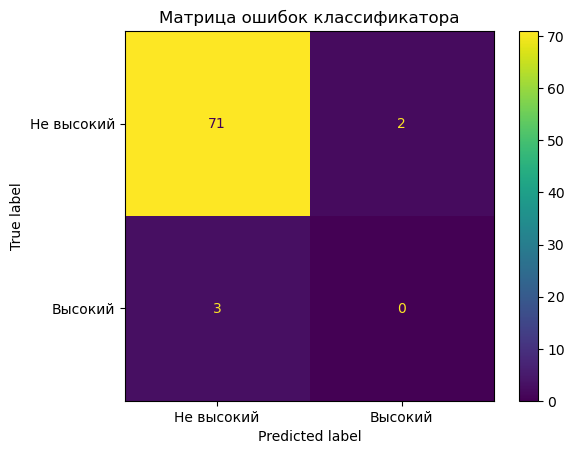

In [23]:

    X_train, X_test, y_train, y_test = train_test_split(
        class_df["description"],
        class_df["high_rating"],
        test_size=0.25,
        random_state=42,
        stratify=class_df["high_rating"]
    )

    classifier = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=3000, min_df=2, ngram_range=(1, 2))),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])

    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)

    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Не высокий рейтинг", "Высокий рейтинг"],
        zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["Не высокий", "Высокий"],
        values_format="d"
    )
    plt.title("Матрица ошибок классификатора")
    plt.show()

Эта матрица наглядно демонстрирует, что предсказать субъективную зрительскую оценку, опираясь исключительно на сухой текст описания сюжета, довольно сложно.

## 14. Итоговая таблица и экспорт результатов

In [24]:
df.to_csv("films_500_analyzed.csv", index=False, encoding="utf-8-sig")
text_df.to_csv("films_text_analysis.csv", index=False, encoding="utf-8-sig")

print("Основная таблица:", df.shape)
print("Фильмы для текстового анализа:", text_df.shape)
display(df.head(10))

Основная таблица: (302, 8)
Фильмы для текстового анализа: (192, 9)


,movie_id,title,year,country,genre,rating,description,main_topic
0,14563620,Непростые отношения,2026.0,Россия,мелодрама,NaN,"Катя — медсестра в частной клинике, одна воспи...",6.0
1,14552734,Страшное кино,2025.0,"Испания, Португалия",документальный,6.3,Во время летних каникул в Лиссабоне режиссер-д...,6.0
2,14555492,Я уезжаю в Виго!,2025.0,Бразилия,документальный,8.4,"О творчестве режиссёра Карлуса Диегиса, которы...",6.0
3,14629255,За закрытыми дверями,2026.0,Россия,мелодрама,NaN,"Желая сбежать от прошлых проблем, Мила вместе ...",2.0
4,14521410,Тень победы,NaN,Россия,детектив,NaN,Лето 1945 года. Бывший учитель Андрей Мартынов...,5.0
5,14555916,Плач осени,2026.0,Китай,мелодрама,9.1,,NaN
6,14540948,Котяткины друзья,2020.0,Россия,"мультфильм, детский",NaN,,NaN
7,14557169,Спутнички,2027.0,Россия,"мультфильм, приключения, семейный",NaN,Планета на грани энергетического коллапса. Пос...,4.0
8,14556138,Народные сказки,2026.0,Россия,"мультфильм, детский",NaN,,NaN
9,14553189,Творимые души,2025.0,Греция,документальный,8.4,"На протяжении 26 лет, с 1972-го по 1998-й, шве...",2.0


Результаты классификации: Модель логистической регрессии показала общую точность (Accuracy) 93.4%, однако метрики для класса "Высокий рейтинг" равны 0.00. Это не является ошибкой кода, а отражает две объективные особенности данных:

Сильный дисбаланс классов: В исходной выборке лишь ~4% фильмов имеют высокий рейтинг. В тестовой выборке оказалось всего 3 таких фильма, что недостаточно для статистически значимого обучения.

Недостаточность текстовых признаков: Сюжетное описание фильма слабо коррелирует с итоговой зрительской оценкой.